# Yapay Sinir Ağları — MLP Midterm | Google Colab Master Notebook
**Student last five digits:** 12902 · **Base seed:** 14928 · **Dataset:** UCI `bank-additional.csv` (4,119 rows).

**Important:** This notebook is an executable research workflow, **not precomputed results**. It can require a long CPU runtime (144+ MLP fits, including final selection and stability checks). Google Colab sessions can disconnect; keep Drive backups. The independent test is deliberately locked until a separate GitHub commit. Run cells sequentially; do not use `Runtime → Run all` across the lock checkpoint.

Outputs are created under `/content/MLP_Midterm_14928/`. At the end, download the project ZIP. All numerical results must come from actual execution.


In [1]:
import os, json, random, time, warnings, pathlib, platform
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.metrics import (average_precision_score, roc_auc_score, accuracy_score, precision_score, recall_score, f1_score, balanced_accuracy_score, confusion_matrix, roc_curve, precision_recall_curve)
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
import torch
from torch import nn
ROOT=pathlib.Path('/content/MLP_Midterm_14928') if pathlib.Path('/content').exists() else pathlib.Path.cwd()
ROOT.mkdir(parents=True,exist_ok=True)
for folder in ['results','figures','configs']: (ROOT/folder).mkdir(exist_ok=True)
STUDENT_LAST5=12902  # Change if needed
SEED=STUDENT_LAST5+2026
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
print('Seed:',SEED,'torch:',torch.__version__,'sklearn:',__import__('sklearn').__version__)

import sklearn, sys
with open(ROOT/'results/environment.json','w') as f: json.dump({'python':sys.version,'torch':torch.__version__,'sklearn':sklearn.__version__,'numpy':np.__version__,'platform':platform.platform(),'seed':SEED,'device':'cpu'},f,indent=2)
torch.set_num_threads(2)


Seed: 14928 torch: 2.14.1+cpu sklearn: 1.6.1


In [2]:
from urllib.request import urlretrieve
from zipfile import ZipFile
DATA=ROOT/'bank-additional.csv'
if not DATA.exists():
    archive=ROOT/'bank-additional.zip'
    urlretrieve('https://archive.ics.uci.edu/static/public/222/bank+marketing.zip',archive)
    with ZipFile(archive) as z:
        nested=z.read('bank-additional.zip')
    import io
    with ZipFile(io.BytesIO(nested)) as z:
        DATA.write_bytes(z.read('bank-additional/bank-additional.csv'))
df=pd.read_csv(DATA,sep=';')
assert df.shape==(4119,21),df.shape
assert set(df.y.unique())=={'yes','no'}
y=df.y.map({'no':0,'yes':1}).astype(int)
X=df.drop(columns=['y','duration'])
idx=np.arange(len(df))
dev_idx,test_idx=train_test_split(idx,test_size=.2,stratify=y,random_state=SEED)
Xdev,ydev=X.iloc[dev_idx].reset_index(drop=True),y.iloc[dev_idx].reset_index(drop=True)
Xtest=X.iloc[test_idx].reset_index(drop=True)  # DO NOT ACCESS TEST LABELS BEFORE LOCKED COMMIT
split=pd.DataFrame({'original_index':np.r_[dev_idx,test_idx],'split':['development']*len(dev_idx)+['test']*len(test_idx),'label':np.r_[y.iloc[dev_idx],np.repeat(np.nan,len(test_idx))]})
split.to_csv(ROOT/'results/dataset_split.csv',index=False)
print('Development',len(dev_idx),'Test',len(test_idx))

assert 'duration' not in Xdev.columns and 'duration' not in Xtest.columns
print('Test labels intentionally unavailable until commit gate.')


Development 3295 Test 824
Test labels intentionally unavailable until commit gate.


## 1. Development-only EDA

Duplicates (development): 17
Class distribution:


,count
y,
no,2934
yes,361


Unknown categories:


,unknown_count
default,631
education,130
housing,80
loan,80
job,27
marital,8
age,0
contact,0
month,0
day_of_week,0


,count,mean,std,min,25%,50%,75%,max
age,3295.0,40.047041,10.325747,18.000,32.000,38.000,47.000,88.000
campaign,3295.0,2.551745,2.581691,1.000,1.000,2.000,3.000,35.000
pdays,3295.0,960.422155,191.922634,0.000,999.000,999.000,999.000,999.000
previous,3295.0,0.188771,0.543378,0.000,0.000,0.000,0.000,6.000
emp.var.rate,3295.0,0.079697,1.566583,-3.400,-1.800,1.100,1.400,1.400
cons.price.idx,3295.0,93.575784,0.581111,92.201,93.075,93.444,93.994,94.767
cons.conf.idx,3295.0,-40.512929,4.616968,-50.800,-42.700,-41.800,-36.400,-26.900
euribor3m,3295.0,3.616086,1.735428,0.635,1.334,4.857,4.961,5.045
nr.employed,3295.0,5166.476328,73.729548,4963.600,5099.100,5191.000,5228.100,5228.100


,unique_values
job,12
marital,4
education,8
default,2
housing,3
loan,3
contact,2
month,10
day_of_week,5
poutcome,3


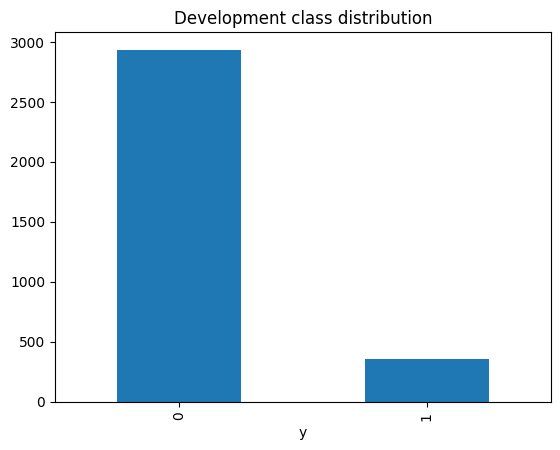

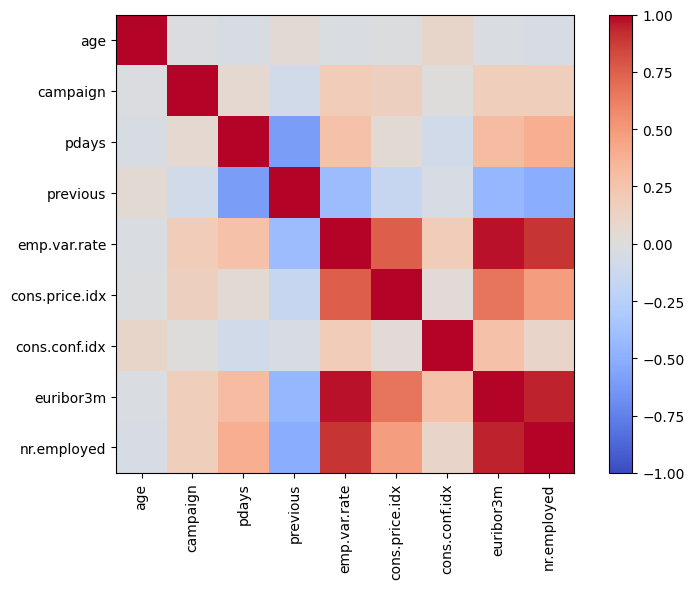

IQR outlier flags (descriptive only, no rows deleted):


,flags
age,31
campaign,192
pdays,128
previous,467
emp.var.rate,0
cons.price.idx,0
cons.conf.idx,38
euribor3m,0
nr.employed,0


Saved histograms, boxplots, category charts and statistics in figures/ and results/.


In [3]:
print('Duplicates (development):',Xdev.duplicated().sum())
print('Class distribution:');display(ydev.value_counts().rename(index={0:'no',1:'yes'}).to_frame('count'))
print('Unknown categories:');display((Xdev=='unknown').sum().sort_values(ascending=False).to_frame('unknown_count'))
num=Xdev.select_dtypes(include=np.number).columns.tolist(); cat=Xdev.select_dtypes(exclude=np.number).columns.tolist()
display(Xdev[num].describe().T)
display(Xdev[cat].nunique().to_frame('unique_values'))
fig,ax=plt.subplots();ydev.value_counts().sort_index().plot.bar(ax=ax);ax.set_title('Development class distribution');fig.savefig(ROOT/'figures/class_distribution.png',bbox_inches='tight');plt.show()
for c in num:
 fig,axs=plt.subplots(1,2,figsize=(9,3));Xdev[c].hist(ax=axs[0],bins=30);Xdev.boxplot(column=c,ax=axs[1]);fig.suptitle(c);fig.tight_layout();fig.savefig(ROOT/f'figures/eda_{c}.png');plt.close(fig)
fig,ax=plt.subplots(figsize=(8,6));corr=Xdev[num].corr();im=ax.imshow(corr,vmin=-1,vmax=1,cmap='coolwarm');ax.set_xticks(range(len(num)),num,rotation=90);ax.set_yticks(range(len(num)),num);fig.colorbar(im);fig.tight_layout();fig.savefig(ROOT/'figures/correlation.png');plt.show()
for c in cat: Xdev[c].value_counts().head(12).to_csv(ROOT/f'results/frequency_{c}.csv')

# Additional reproducible EDA tables and figures (development only)
summary=Xdev[num].describe().T
summary['IQR']=summary['75%']-summary['25%']
summary.to_csv(ROOT/'results/numeric_descriptive_statistics.csv')
(Xdev.isna().sum()).to_csv(ROOT/'results/missing_counts.csv')
(Xdev=='unknown').sum().to_csv(ROOT/'results/unknown_counts.csv')
q1=Xdev[num].quantile(.25);q3=Xdev[num].quantile(.75);iqr=q3-q1
outlier=((Xdev[num].lt(q1-1.5*iqr)) | (Xdev[num].gt(q3+1.5*iqr))).sum()
outlier.to_csv(ROOT/'results/iqr_outlier_flags.csv')
print('IQR outlier flags (descriptive only, no rows deleted):');display(outlier.to_frame('flags'))
for c in cat[:5]:
 fig,ax=plt.subplots(figsize=(8,3));Xdev[c].value_counts().head(10).plot.bar(ax=ax);ax.set_title('Development: '+c);fig.tight_layout();fig.savefig(ROOT/f'figures/category_{c}.png');plt.close(fig)
for c in ['age','campaign','euribor3m']:
 fig,ax=plt.subplots(figsize=(7,3));pd.DataFrame({'feature':Xdev[c],'target':ydev}).boxplot(column='feature',by='target',ax=ax);fig.suptitle('');fig.tight_layout();fig.savefig(ROOT/f'figures/by_target_{c}.png');plt.close(fig)
print('Saved histograms, boxplots, category charts and statistics in figures/ and results/.')


### Pre-registered hypotheses (before outer CV)
**H1:** StandardScaler may improve AP compared with MinMaxScaler.  
**H2:** AdamW, Adam and SGD+Momentum have different convergence behavior at the same learning rate.  
**H3:** Two hidden layers may improve AP but may increase overfitting.  
`unknown` is a distinct category; `pdays=999` means no previous contact and is preserved. MinMax normalization and z-score standardization are different operations. These hypotheses must be evaluated, not presumed true.


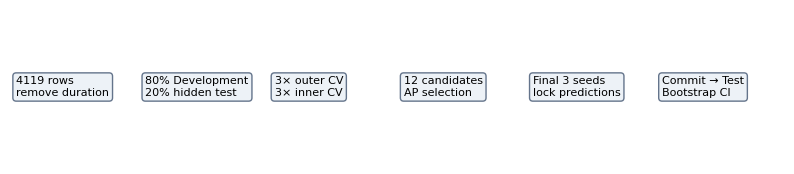

In [4]:
import matplotlib.pyplot as plt
fig,ax=plt.subplots(figsize=(10,2));ax.axis('off')
labels=['4119 rows\nremove duration','80% Development\n20% hidden test','3× outer CV\n3× inner CV','12 candidates\nAP selection','Final 3 seeds\nlock predictions','Commit → Test\nBootstrap CI']
for i,s in enumerate(labels):
 x=i/6+.008
 ax.text(x,.5,s,ha='left',va='center',fontsize=8,bbox={'boxstyle':'round','fc':'#edf2f7','ec':'#64748b'})
fig.savefig(ROOT/'figures/nested_cv_flow.png',bbox_inches='tight');plt.show()


## 2. Fold-local PyTorch MLP engine

In [5]:
# Shared modeling engine — run in 02_nested_cv.ipynb
from dataclasses import dataclass
import copy
from sklearn.base import BaseEstimator,TransformerMixin
class ClipQuantiles(BaseEstimator,TransformerMixin):
 def __init__(self,enabled=False):self.enabled=enabled
 def fit(self,X,y=None):
  a=np.asarray(X,dtype=float)
  if self.enabled:self.lo_=np.nanpercentile(a,1,axis=0);self.hi_=np.nanpercentile(a,99,axis=0)
  return self
 def transform(self,X):
  a=np.asarray(X,dtype=float)
  return np.clip(a,self.lo_,self.hi_) if self.enabled else a

def preprocess(cfg,Xfit):
 nums=Xfit.select_dtypes(include=np.number).columns.tolist()
 cats=Xfit.select_dtypes(exclude=np.number).columns.tolist()
 scale={'Standard':'StandardScaler','MinMax':'MinMaxScaler','Robust':'RobustScaler'}
 scaler={'Standard':StandardScaler,'MinMax':MinMaxScaler,'Robust':RobustScaler}[cfg['scaler']]()
 numeric=Pipeline([('clip',ClipQuantiles(cfg.get('clip',False))),('impute',SimpleImputer(strategy='median')),('scale',scaler)])
 categorical=Pipeline([('impute',SimpleImputer(strategy='most_frequent')),('encode',OneHotEncoder(handle_unknown='ignore'))])
 # pdays=999 is a meaningful sentinel; do not percentile-clip that column.
 special=['pdays'] if 'pdays' in nums else []
 regular=[c for c in nums if c!='pdays']
 transformers=[]
 if regular:transformers.append(('numeric',numeric,regular))
 if special:transformers.append(('pdays',Pipeline([('impute',SimpleImputer(strategy='median')),('scale',{'Standard':StandardScaler,'MinMax':MinMaxScaler,'Robust':RobustScaler}[cfg['scaler']]())]),special))
 if cats:transformers.append(('categorical',categorical,cats))
 return ColumnTransformer(transformers,sparse_threshold=0)
class Net(nn.Module):
 def __init__(self,d,cfg):
  super().__init__(); layers=[]; act=nn.ReLU if cfg['activation']=='relu' else nn.Tanh
  for h in cfg['hidden']:
   layers.extend([nn.Linear(d,h),act(),nn.Dropout(cfg['dropout'])]);d=h
  layers.append(nn.Linear(d,1));self.net=nn.Sequential(*layers)
 def forward(self,x):return self.net(x).squeeze(-1)
def fit_model(Xtr,ytr,cfg,seed,tag):
 torch.manual_seed(seed);np.random.seed(seed);random.seed(seed)
 fit_ids,mon_ids=train_test_split(np.arange(len(ytr)),test_size=.15,stratify=ytr,random_state=seed)
 pp=preprocess(cfg,Xtr.iloc[fit_ids]);pp.fit(Xtr.iloc[fit_ids])
 a=np.asarray(pp.transform(Xtr.iloc[fit_ids]),dtype=np.float32)
 b=np.asarray(pp.transform(Xtr.iloc[mon_ids]),dtype=np.float32)
 ya=np.asarray(ytr.iloc[fit_ids],dtype=np.float32);yb=np.asarray(ytr.iloc[mon_ids],dtype=np.float32)
 net=Net(a.shape[1],cfg)
 optclass={'AdamW':torch.optim.AdamW,'Adam':torch.optim.Adam,'SGD':torch.optim.SGD}[cfg['optimizer']]
 kw={'lr':cfg['lr'],'weight_decay':cfg['wd']}
 if cfg['optimizer']=='SGD':kw['momentum']=.9
 opt=optclass(net.parameters(),**kw)
 scheduler=torch.optim.lr_scheduler.ReduceLROnPlateau(opt,mode='min',factor=.5,patience=5,min_lr=1e-5) if cfg['scheduler'] else None
 lossfn=nn.BCEWithLogitsLoss();best=float('inf');wait=0;history=[];start=time.time()
 dataset=torch.utils.data.TensorDataset(torch.tensor(a),torch.tensor(ya))
 loader=torch.utils.data.DataLoader(dataset,batch_size=cfg['batch'],shuffle=True,generator=torch.Generator().manual_seed(seed))
 for epoch in range(1,151):
  net.train();losses=[]
  for xx,yy in loader:
   opt.zero_grad();loss=lossfn(net(xx),yy);loss.backward();opt.step();losses.append(loss.item())
  net.eval()
  with torch.no_grad(): val=lossfn(net(torch.tensor(b)),torch.tensor(yb)).item()
  lr=opt.param_groups[0]['lr'];history.append({'epoch':epoch,'train_loss':float(np.mean(losses)),'monitor_loss':val,'lr':lr})
  if val<best-1e-6:best=val;state=copy.deepcopy(net.state_dict());best_epoch=epoch;wait=0
  else:wait+=1
  if scheduler:scheduler.step(val)
  if wait>=15:break
 net.load_state_dict(state)
 pd.DataFrame(history).to_csv(ROOT/'results'/f'{tag}_history.csv',index=False)
 return pp,net,{'best_epoch':best_epoch,'elapsed_s':time.time()-start,'parameters':sum(t.numel() for t in net.parameters())}
def predict_prob(model,X):
 pp,net,_=model;net.eval()
 with torch.no_grad():return torch.sigmoid(net(torch.tensor(np.asarray(pp.transform(X),dtype=np.float32)))).numpy()
def metrics(y,p):
 pred=(p>=.5).astype(int);tn,fp,fn,tp=confusion_matrix(y,pred,labels=[0,1]).ravel()
 return dict(AP=average_precision_score(y,p),ROC_AUC=roc_auc_score(y,p),Accuracy=accuracy_score(y,pred),Precision=precision_score(y,pred,zero_division=0),Sensitivity=recall_score(y,pred,zero_division=0),Specificity=tn/(tn+fp),F1=f1_score(y,pred,zero_division=0),Balanced_Accuracy=balanced_accuracy_score(y,pred))
def candidate_eval(X,y,cfg,folds,tag,seed):
 scores=[];times=[];epochs=[]
 for j,(tr,va) in enumerate(folds):
  m=fit_model(X.iloc[tr].reset_index(drop=True),y.iloc[tr].reset_index(drop=True),cfg,seed+j,f'{tag}_inner{j}')
  scores.append(average_precision_score(y.iloc[va],predict_prob(m,X.iloc[va])));times.append(m[2]['elapsed_s']);epochs.append(m[2]['best_epoch'])
 return {'mean_AP':float(np.mean(scores)),'sd_AP':float(np.std(scores,ddof=1)),'time_s':float(sum(times)),'best_epoch_mean':float(np.mean(epochs))}


## 3. Freeze 6 manual + 6 random candidates

In [6]:
base=dict(optimizer='AdamW',hidden=(32,),scaler='Standard',lr=.001,wd=1e-4,scheduler=True,batch=64,dropout=0.,activation='relu',clip=False)
manual={f'M{i}':dict(base) for i in range(1,7)}
manual['M2']['optimizer']='Adam';manual['M3']['optimizer']='SGD';manual['M4']['scaler']='MinMax';manual['M5']['hidden']=(64,32);manual['M6']['scheduler']=False
rng=np.random.default_rng(SEED)
random_cfg={}
for opt in ['SGD','Adam','AdamW']:
 for j in range(2):
  cfg=dict(optimizer=opt,hidden=tuple([(16,),(32,),(64,),(64,32),(128,64)][rng.integers(5)]),activation=str(rng.choice(['relu','tanh'])),lr=float(10**rng.uniform(-3,-1) if opt=='SGD' else 10**rng.uniform(-4,-2)),wd=float(rng.choice([0,1e-5,1e-4,1e-3])),batch=int(rng.choice([32,64,128])),scaler=str(rng.choice(['Standard','MinMax','Robust'])),dropout=float(rng.choice([0,.2])),clip=bool(rng.choice([False,True])),scheduler=True)
  random_cfg[f'R{len(random_cfg)+1}']=cfg
with open(ROOT/'configs/candidates.json','w') as f:json.dump({'manual':manual,'random':random_cfg,'seed':SEED},f,indent=2)
print('Candidates frozen in configs/candidates.json')


Candidates frozen in configs/candidates.json


## 4. Outer 3-fold × inner 3-fold nested CV (long runtime)

Outer fold completed: 1
Outer fold completed: 2
Outer fold completed: 3


AP             ROC_AUC                  F1  \
                        mean       std      mean       std      mean   
method                                                                 
Dummy               0.109560  0.000468  0.500000  0.000000  0.000000   
LogisticRegression  0.408693  0.005944  0.757330  0.016261  0.333861   
manual              0.414511  0.024470  0.763363  0.019219  0.313810   
random              0.397205  0.022758  0.761184  0.023726  0.220915   

                             Sensitivity           Specificity            \
                         std        mean       std        mean       std   
method                                                                     
Dummy               0.000000    0.000000  0.000000    1.000000  0.000000   
LogisticRegression  0.014195    0.232668  0.013893    0.980232  0.003287   
manual              0.012630    0.207782  0.009172    0.985685  0.001022   
random              0.191328    0.155556  0.134715    0.985685  0.012439   

                   Balanced_Accuracy            
                                mean       std  
method                                          
Dummy                       0.500000  0.000000  
LogisticRegression          0.606450  0.006158  
manual                      0.596734  0.004840  
random                      0.570620  0.061161

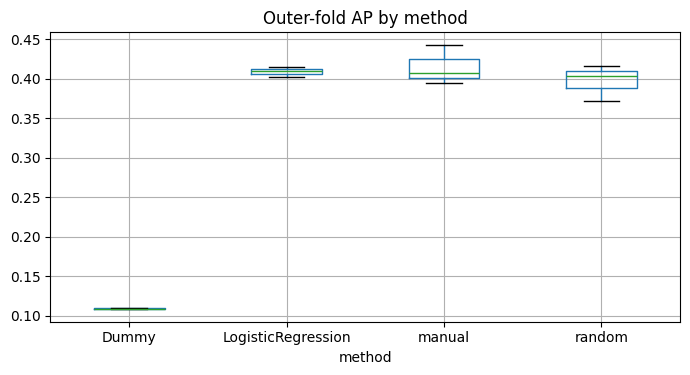

In [7]:
outer=StratifiedKFold(n_splits=3,shuffle=True,random_state=SEED+1)
outer_rows=[];search_rows=[]
for oi,(otr,ova) in enumerate(outer.split(Xdev,ydev),1):
 xx=Xdev.iloc[otr].reset_index(drop=True);yy=ydev.iloc[otr].reset_index(drop=True)
 inner=list(StratifiedKFold(n_splits=3,shuffle=True,random_state=SEED+100+oi).split(xx,yy))
 for method,candidates in [('manual',manual),('random',random_cfg)]:
  scored=[]
  for name,cfg in candidates.items():
   result=candidate_eval(xx,yy,cfg,inner,f'outer{oi}_{name}_{name}',SEED+oi*1000)
   row={'outer_fold':oi,'method':method,'candidate':name,**result,**{k:str(v) for k,v in cfg.items()}}
   search_rows.append(row);scored.append((result['mean_AP'],name))
  winner=max(scored,key=lambda z:z[0])[1]
  chosen=candidates[winner]
  m=fit_model(xx,yy,chosen,SEED+oi,f'outer{oi}_{method}_refit')
  out=metrics(ydev.iloc[ova],predict_prob(m,Xdev.iloc[ova]))
  outer_rows.append({'outer_fold':oi,'method':method,'candidate':winner,**out,**m[2]})
 for name,model in [('Dummy',DummyClassifier(strategy='prior')),('LogisticRegression',LogisticRegression(max_iter=2000,random_state=SEED))]:
  pp=preprocess(base,xx);a=pp.fit_transform(xx);b=pp.transform(Xdev.iloc[ova]);model.fit(a,yy)
  pr=model.predict_proba(b)[:,1]
  outer_rows.append({'outer_fold':oi,'method':name,'candidate':'fixed',**metrics(ydev.iloc[ova],pr)})
 pd.DataFrame(search_rows).to_csv(ROOT/'results/search_all_folds.csv',index=False)
 pd.DataFrame(outer_rows).to_csv(ROOT/'results/outer_cv_results.csv',index=False)
 print('Outer fold completed:',oi)
res=pd.DataFrame(search_rows)
for method in ['manual','random']:
 res[res.method==method].to_csv(ROOT/'results'/f'{method}_search_results.csv',index=False)
outer_df=pd.DataFrame(outer_rows)
summary=outer_df.groupby('method')[['AP','ROC_AUC','F1','Sensitivity','Specificity','Balanced_Accuracy']].agg(['mean','std'])
display(summary);summary.to_csv(ROOT/'results/outer_cv_summary.csv')

# Comparison chart (outer evaluation AP, no tuning on outer scores)
fig,ax=plt.subplots(figsize=(7,4));outer_df.boxplot(column='AP',by='method',ax=ax);fig.suptitle('');ax.set_title('Outer-fold AP by method');fig.tight_layout();fig.savefig(ROOT/'figures/outer_method_AP.png');plt.show()


## 5. Fresh development-only 3-fold inner CV for final selection

Selected: manual M5 AP: 0.4321032264404086


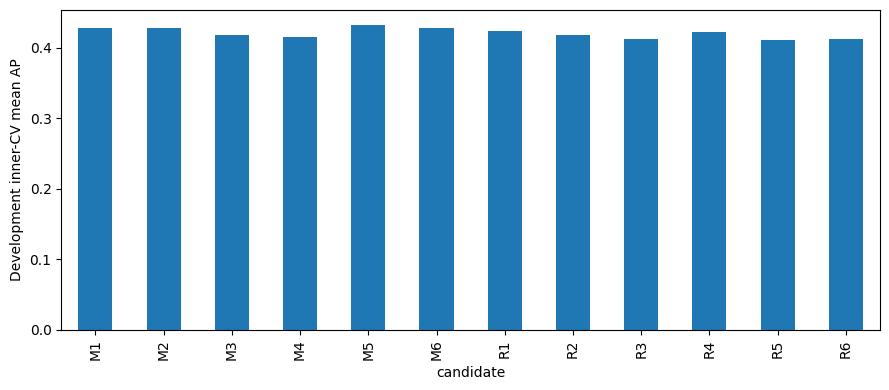

In [8]:
# Fresh inner CV over ALL development; do not select using outer results
folds=list(StratifiedKFold(n_splits=3,shuffle=True,random_state=SEED+500).split(Xdev,ydev))
final_rows=[]
for method,candidates in [('manual',manual),('random',random_cfg)]:
 for name,cfg in candidates.items():
  r=candidate_eval(Xdev,ydev,cfg,folds,f'final_{name}',SEED+600)
  final_rows.append({'method':method,'candidate':name,**r})
final_df=pd.DataFrame(final_rows);final_df.to_csv(ROOT/'results/final_selection.csv',index=False)
w=final_df.sort_values('mean_AP',ascending=False).iloc[0]
selected=(manual if w.method=='manual' else random_cfg)[w.candidate]
with open(ROOT/'results/final_hyperparameters.json','w') as f:json.dump({'method':w.method,'candidate':w.candidate,'config':selected,'primary_seed':SEED},f,indent=2)
print('Selected:',w.method,w.candidate,'AP:',w.mean_AP)

fig,ax=plt.subplots(figsize=(9,4));final_df.set_index('candidate')['mean_AP'].plot.bar(ax=ax);ax.set_ylabel('Development inner-CV mean AP');fig.tight_layout();fig.savefig(ROOT/'figures/manual_random_comparison.png');plt.show()


## 6. Final training: three fixed seeds and unlabeled test predictions

LOCKED predictions created, without labels. Commit this CSV, config and code to GitHub BEFORE running the next notebook cell.


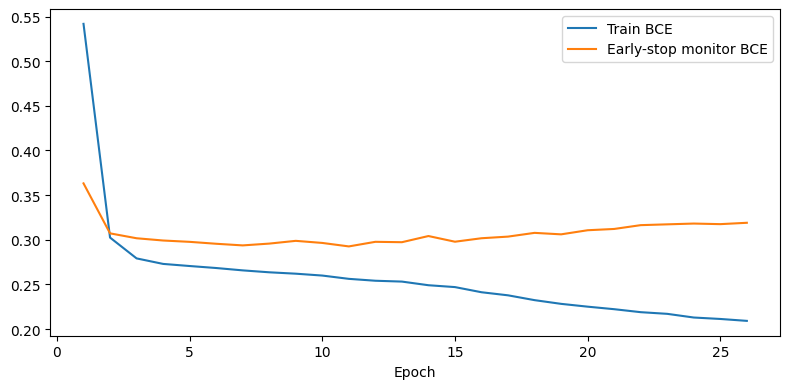

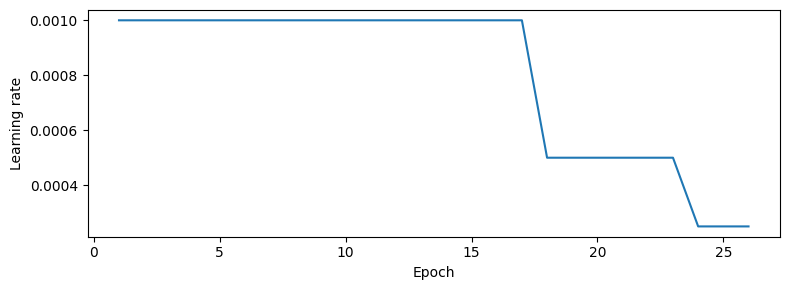

In [9]:
with open(ROOT/'results/final_hyperparameters.json') as f: selection=json.load(f)
cfg=selection['config']; seeds=[SEED,SEED+1,SEED+2]
models=[];locked=pd.DataFrame({'original_index':test_idx})
for i,seed in enumerate(seeds):
 model=fit_model(Xdev,ydev,cfg,seed,f'final_seed_{seed}')
 models.append(model)
 import joblib
 joblib.dump(model[0],ROOT/'results'/f'preprocessor_seed_{seed}.joblib')
 torch.save({'state_dict':model[1].state_dict(),'config':cfg,'seed':seed,'parameters':model[2]['parameters']},ROOT/'results'/f'model_seed_{seed}.pt')
 prob=predict_prob(model,Xtest)
 locked[f'prob_seed_{seed}']=prob
 locked[f'prediction_seed_{seed}']=(prob>=.5).astype(int)
locked.to_csv(ROOT/'results/test_predictions_locked.csv',index=False)
print('LOCKED predictions created, without labels. Commit this CSV, config and code to GitHub BEFORE running the next notebook cell.')

# Save learning curves and architecture summary from primary seed
hist=pd.read_csv(ROOT/'results'/f'final_seed_{SEED}_history.csv')
fig,ax=plt.subplots(figsize=(8,4));ax.plot(hist.epoch,hist.train_loss,label='Train BCE');ax.plot(hist.epoch,hist.monitor_loss,label='Early-stop monitor BCE');ax.legend();ax.set_xlabel('Epoch');fig.tight_layout();fig.savefig(ROOT/'figures/final_training_losses.png');plt.show()
fig,ax=plt.subplots(figsize=(8,3));ax.plot(hist.epoch,hist.lr);ax.set(xlabel='Epoch',ylabel='Learning rate');fig.tight_layout();fig.savefig(ROOT/'figures/final_learning_rate.png');plt.show()
with open(ROOT/'results/model_architecture.json','w') as f:json.dump({'hidden':cfg['hidden'],'input_features':models[0][1].net[0].in_features,'learnable_parameters':models[0][2]['parameters']},f,indent=2)


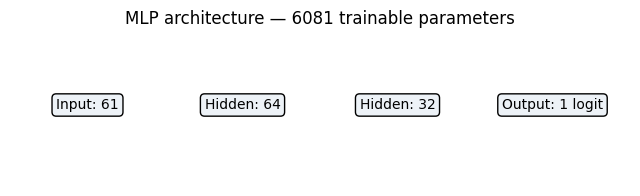

In [10]:
fig,ax=plt.subplots(figsize=(8,2));ax.axis('off')
items=[f"Input: {models[0][1].net[0].in_features}"]+[f"Hidden: {v}" for v in cfg['hidden']]+['Output: 1 logit']
for i,s in enumerate(items):ax.text((i+.5)/len(items),.5,s,ha='center',bbox={'boxstyle':'round','fc':'#edf2f7'})
ax.set_title(f"MLP architecture — {models[0][2]['parameters']} trainable parameters")
fig.savefig(ROOT/'figures/mlp_architecture.png',bbox_inches='tight');plt.show()


In [15]:
import os

for root, dirs, files in os.walk("/content"):
    if "test_predictions_locked.csv" in files:
        print("Found:", os.path.join(root, "test_predictions_locked.csv"))

Found: /content/MLP_Midterm_14928/results/test_predictions_locked.csv


## STOP — Mandatory separate GitHub commit
1. Download/save `results/test_predictions_locked.csv`, `results/final_hyperparameters.json`, configuration and source code to your GitHub repository.
2. Make a **separate commit** of these files **before** looking at test labels or scores.
3. Record the commit hash in your report. Only then change `CONFIRM_LOCKED_COMMIT=False` to `True` in the next cell and execute it.

**Do not run all cells automatically through this checkpoint.** The CSV must have no target label column.


In [14]:
print("ROOT:", ROOT)
print("Files:", os.listdir(ROOT / "results"))

ROOT: /content/MLP_Midterm_14928
Files: ['outer1_M3_M3_inner2_history.csv', 'outer2_R1_R1_inner1_history.csv', 'frequency_contact.csv', 'outer3_M4_M4_inner1_history.csv', 'outer2_R5_R5_inner0_history.csv', 'outer1_R4_R4_inner1_history.csv', 'outer1_M1_M1_inner2_history.csv', 'outer2_R2_R2_inner1_history.csv', 'outer2_M1_M1_inner0_history.csv', 'outer_cv_summary.csv', 'outer3_R2_R2_inner2_history.csv', 'outer2_M6_M6_inner0_history.csv', 'outer2_R5_R5_inner1_history.csv', 'final_M5_inner1_history.csv', 'missing_counts.csv', 'final_M1_inner1_history.csv', 'outer1_manual_refit_history.csv', 'outer3_R6_R6_inner1_history.csv', 'outer2_R3_R3_inner0_history.csv', 'final_R2_inner1_history.csv', 'outer1_R4_R4_inner0_history.csv', 'outer3_M6_M6_inner0_history.csv', 'outer2_manual_refit_history.csv', 'final_R4_inner0_history.csv', 'final_seed_14928_history.csv', 'outer1_R1_R1_inner0_history.csv', 'iqr_outlier_flags.csv', 'outer1_M5_M5_inner1_history.csv', 'frequency_month.csv', 'test_predictions_l

In [16]:
# DO NOT RUN BEFORE GitHub commit of locked predictions.
# Confirm the commit yourself. This gate prevents accidental early scoring.
CONFIRM_LOCKED_COMMIT=False  # ONLY change after separate GitHub commit
assert CONFIRM_LOCKED_COMMIT, 'First commit test_predictions_locked.csv and code to GitHub; then set CONFIRM_LOCKED_COMMIT=True.'
ytest=y.iloc[test_idx].reset_index(drop=True)  # FIRST test-label access, after confirmation
from sklearn.metrics import ConfusionMatrixDisplay
rows=[]
for i,seed in enumerate(seeds):
 pr=locked[f'prob_seed_{seed}'].to_numpy();rows.append({'model':f'MLP_seed_{seed}',**metrics(ytest,pr)})
 # Primary model graphics
 if i==0:
  fig,ax=plt.subplots();ConfusionMatrixDisplay.from_predictions(ytest,pr>=.5,ax=ax);fig.savefig(ROOT/'figures/mlp_confusion.png');plt.show()
  fpr,tpr,_=roc_curve(ytest,pr);precision,recall,_=precision_recall_curve(ytest,pr)
  fig,ax=plt.subplots();ax.plot(fpr,tpr,label='MLP');ax.set(xlabel='FPR',ylabel='TPR');ax.legend();fig.savefig(ROOT/'figures/mlp_roc.png');plt.show()
  fig,ax=plt.subplots();ax.plot(recall,precision,label='MLP');ax.set(xlabel='Recall',ylabel='Precision');ax.legend();fig.savefig(ROOT/'figures/mlp_pr.png');plt.show()
  boot=[];rng=np.random.default_rng(SEED+900);yy=ytest.to_numpy()
  for _ in range(1000):
   ids=rng.integers(0,len(yy),len(yy))
   if len(np.unique(yy[ids]))<2:continue
   boot.append(metrics(yy[ids],pr[ids]))
  ci={k:np.percentile([b[k] for b in boot],[2.5,97.5]).tolist() for k in ['AP','ROC_AUC','F1']}
  with open(ROOT/'results/bootstrap_ci.json','w') as f:json.dump(ci,f,indent=2)
  print('Bootstrap 95% CI',ci)
  fp=int(((pr>=.5)&(yy==0)).sum());fn=int(((pr<.5)&(yy==1)).sum());print('False positives:',fp,'False negatives:',fn)
# Baselines: training uses development only
for name,est in [('Dummy',DummyClassifier(strategy='prior')),('LogisticRegression',LogisticRegression(max_iter=2000,random_state=SEED))]:
 pp=preprocess(dict(scaler='Standard',clip=False),Xdev);aa=pp.fit_transform(Xdev);bb=pp.transform(Xtest);est.fit(aa,ydev);pr=est.predict_proba(bb)[:,1]
 rows.append({'model':name,**metrics(ytest,pr)})
 if name=='LogisticRegression':
  fig,ax=plt.subplots();ConfusionMatrixDisplay.from_predictions(ytest,pr>=.5,ax=ax);fig.savefig(ROOT/'figures/logistic_confusion.png');plt.show()
  fpr,tpr,_=roc_curve(ytest,pr);fig,ax=plt.subplots();ax.plot(fpr,tpr,label='Logistic Regression');ax.legend();fig.savefig(ROOT/'figures/logistic_roc.png');plt.show()
  prec,rec,_=precision_recall_curve(ytest,pr);fig,ax=plt.subplots();ax.plot(rec,prec,label='Logistic Regression');ax.legend();fig.savefig(ROOT/'figures/logistic_pr.png');plt.show()
result=pd.DataFrame(rows);result.to_csv(ROOT/'results/test_metrics.csv',index=False)
result[result.model.str.startswith('MLP')].to_csv(ROOT/'results/seed_stability_results.csv',index=False)
display(result)

# Descriptive seed stability summary, not independent confidence intervals
seed_rows=result[result.model.str.startswith('MLP')]
seed_rows.select_dtypes(include='number').agg(['mean','std']).to_csv(ROOT/'results/seed_stability_summary.csv')
# Bootstrap table
pd.DataFrame([{'metric':k,'lower_95':v[0],'upper_95':v[1]} for k,v in ci.items()]).to_csv(ROOT/'results/bootstrap_ci.csv',index=False)
# Error analysis (aggregate only)
primary=locked[f'prob_seed_{SEED}'].to_numpy(); pred=(primary>=.5).astype(int)
pd.DataFrame([{'error_type':'false_positive','count':int(((pred==1)&(ytest.to_numpy()==0)).sum())},{'error_type':'false_negative','count':int(((pred==0)&(ytest.to_numpy()==1)).sum())}]).to_csv(ROOT/'results/error_analysis.csv',index=False)
print('Test evaluation completed. Export results/ and figures/ for the Turkish scientific report.')


AssertionError: First commit test_predictions_locked.csv and code to GitHub; then set CONFIRM_LOCKED_COMMIT=True.

## 7. Export project files (after scoring)

In [ ]:
import shutil
archive=shutil.make_archive('/content/MLP_Midterm_14928_results','zip',ROOT)
print('Download:',archive)
try:
 from google.colab import files
 files.download(archive)
except ImportError:
 print('Archive saved:',archive)
